# 04 — Huấn luyện & đánh giá

## Thiết kế thực nghiệm (theo các quyết định từ EDA)

| Thành phần | Lựa chọn | Lý do |
|---|---|---|
| Mô hình | **LightGBM** (GBDT) | quan hệ phi tuyến, nhiều tương tác, dữ liệu 1,37M dòng |
| Objective | **L1 (MAE)** | metric quan tâm là sai số tuyệt đối; bền với outlier tuổi |
| Số fold | 5-fold KFold (shuffle, seed 42) | đủ ổn định, chi phí hợp lý |
| Mẫu train mỗi fold | 700.000 / 1.084.895 | cân bằng thời gian và độ chính xác (kiểm tra: tăng lên 1,08M chỉ cải thiện <0,01 MAE) |
| Encoding | tính lại mỗi fold | chống rò rỉ (notebook 03) |
| Baseline | median toàn cục, postal-code median (OOF) | để biết mô hình có học được gì không |

## Hai chế độ chạy

Notebook hỗ trợ cả hai, mặc định là chế độ "dùng lại kết quả" để người đọc không phải chờ 27 phút:

```python
TRAIN_FROM_SCRATCH = False   # True -> chạy đầy đủ 5 fold (~27 phút, cần ~4 GB RAM)
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

# Notebook có thể được mở từ thư mục notebooks/ hoặc từ gốc repo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

DATA = ROOT / "data"
CUSTOMERS = DATA / "customers.csv"
ARTICLES = DATA / "articles.csv"
TXN = DATA / "transactions_train.csv"
ARTIFACTS = ROOT / "artifacts"
OUTPUTS = ROOT / "outputs"
REPORTS = ROOT / "reports"

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
print("polars", pl.__version__, "| numpy", np.__version__, "| ROOT =", ROOT)

polars 2.1.0 | numpy 2.3.5 | ROOT = E:\download\age_imputation


In [2]:
import json
import time

import lightgbm as lgb
import numpy as np
import polars as pl
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold

import src.config as C
from src.dataset import load
from src.target_encoding import TargetEncoder

TRAIN_FROM_SCRATCH = False   # đổi thành True để chạy lại toàn bộ 5 fold

X, y, base_names = load()
encoder = TargetEncoder(y.size)
names = base_names + encoder.names
labeled = np.flatnonzero(~np.isnan(y))
print(f"X: {X.shape} | tổng feature: {len(names)} | khách có nhãn: {labeled.size:,}")
print("tham số LightGBM:", C.LGB_PARAMS)

X: (1371980, 96) | tổng feature: 105 | khách có nhãn: 1,356,119
tham số LightGBM: {'objective': 'regression_l1', 'metric': 'mae', 'learning_rate': 0.03, 'num_leaves': 63, 'min_data_in_leaf': 300, 'feature_fraction': 0.7, 'bagging_fraction': 0.8, 'bagging_freq': 1, 'lambda_l2': 1.0, 'max_bin': 127, 'verbosity': -1, 'seed': 42}


## Hàm đánh giá

Ngoài MAE/RMSE/R², ta đo thêm hai thứ có ý nghĩa thực tế:

- **Đúng nhóm tuổi**: chia 7 nhóm (16–19, 20–29, ..., 70+) — dùng cho marketing/báo cáo.
- **Sai ≤ 5 tuổi / ≤ 10 tuổi**: tỷ lệ khách được điền "đủ tốt".

In [3]:
def age_bucket(v: np.ndarray) -> np.ndarray:
    return np.digitize(v, C.AGE_BINS[1:-1])


def evaluate(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    y_pred = np.clip(y_pred, C.AGE_MIN, C.AGE_MAX)
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
        "bucket_acc": float((age_bucket(y_true) == age_bucket(y_pred)).mean()),
        "within_5y": float((np.abs(y_true - y_pred) <= 5).mean()),
        "within_10y": float((np.abs(y_true - y_pred) <= 10).mean()),
    }

## Vòng lặp cross-validation

Mỗi fold gồm 4 bước: (1) tính encoding từ nhãn tập train, (2) ghép ma trận, (3) train với early
stopping trên tập validation, (4) lưu dự đoán out-of-fold (OOF).

OOF rất quan trọng: mỗi khách được dự đoán bởi model **chưa từng thấy** nhãn của họ, nên metric
tổng hợp là ước lượng công bằng.

In [4]:
def run_cv() -> tuple[np.ndarray, list[dict], list[int]]:
    oof = np.full(y.size, np.nan, dtype=np.float32)
    folds, iters = [], []
    kf = KFold(n_splits=C.N_SPLITS, shuffle=True, random_state=C.RANDOM_STATE)

    for fold, (tr_pos, va_pos) in enumerate(kf.split(labeled), 1):
        tr_idx, va_idx = labeled[tr_pos], labeled[va_pos]
        if C.TRAIN_SAMPLE < tr_idx.size:
            rng = np.random.default_rng(C.RANDOM_STATE + fold)
            fit_idx = np.sort(rng.choice(tr_idx, C.TRAIN_SAMPLE, replace=False))
        else:
            fit_idx = tr_idx

        train_mask = np.zeros(y.size, bool)
        train_mask[tr_idx] = True
        te_fold = encoder.transform(train_mask, y)

        n_feat = X.shape[1]
        X_tr = np.empty((fit_idx.size, n_feat + te_fold.shape[1]), dtype=np.float32)
        X_va = np.empty((va_idx.size, n_feat + te_fold.shape[1]), dtype=np.float32)
        for s in range(0, fit_idx.size, 200_000):
            chunk = fit_idx[s : s + 200_000]
            X_tr[s : s + 200_000, :n_feat] = X[chunk]
            X_tr[s : s + 200_000, n_feat:] = te_fold[chunk]
        X_va[:, :n_feat] = X[va_idx]
        X_va[:, n_feat:] = te_fold[va_idx]

        dtrain = lgb.Dataset(X_tr, label=y[fit_idx], feature_name=names, free_raw_data=True)
        dvalid = lgb.Dataset(X_va, label=y[va_idx], reference=dtrain, free_raw_data=True)
        model = lgb.train(
            C.LGB_PARAMS,
            dtrain,
            num_boost_round=C.NUM_BOOST_ROUND,
            valid_sets=[dvalid],
            valid_names=["val"],
            callbacks=[lgb.early_stopping(C.EARLY_STOPPING, verbose=False)],
        )
        pred = model.predict(X_va, num_iteration=model.best_iteration)
        oof[va_idx] = pred

        m = evaluate(y[va_idx], pred)
        m.update(fold=fold, best_iter=model.best_iteration)
        folds.append(m)
        iters.append(model.best_iteration)
        print(f"fold {fold}: MAE={m['mae']:.4f} R2={m['r2']:.4f} iter={m['best_iter']}", flush=True)
        del X_tr, X_va, dtrain, dvalid, model

    return oof, folds, iters

In [5]:
if TRAIN_FROM_SCRATCH:
    t0 = time.time()
    oof, fold_metrics, best_iters = run_cv()
    runtime = time.time() - t0
    np.save(OUTPUTS / "oof_pred.npy", oof)
    print(f"tổng thời gian: {runtime / 60:.1f} phút")
else:
    oof = np.load(OUTPUTS / "oof_pred.npy")
    metrics = json.loads((REPORTS / "metrics.json").read_text())
    fold_metrics, best_iters = metrics["folds"], metrics["best_iterations"]
    print("Đã nạp dự đoán OOF và metric có sẵn (TRAIN_FROM_SCRATCH = False)")

Đã nạp dự đoán OOF và metric có sẵn (TRAIN_FROM_SCRATCH = False)


## Kết quả từng fold

5 fold cho kết quả rất ổn định — dấu hiệu mô hình không phụ thuộc vào một cách chia dữ liệu may rủi.

In [6]:
table = pl.DataFrame(
    {
        "fold": [f["fold"] for f in fold_metrics],
        "MAE": [round(f["mae"], 3) for f in fold_metrics],
        "RMSE": [round(f["rmse"], 3) for f in fold_metrics],
        "R2": [round(f["r2"], 4) for f in fold_metrics],
        "đúng nhóm tuổi": [round(f["bucket_acc"] * 100, 1) for f in fold_metrics],
        "sai ≤5 tuổi": [round(f["within_5y"] * 100, 1) for f in fold_metrics],
        "sai ≤10 tuổi": [round(f["within_10y"] * 100, 1) for f in fold_metrics],
        "số cây": [f["best_iter"] for f in fold_metrics],
    }
)
table

fold,MAE,RMSE,R2,đúng nhóm tuổi,sai ≤5 tuổi,sai ≤10 tuổi,số cây
i64,f64,f64,f64,f64,f64,f64,i64
1,8.782,12.263,0.2655,43.7,46.0,68.2,4000
2,8.811,12.318,0.26,43.6,46.1,68.2,4000
3,8.795,12.295,0.2638,43.6,46.2,68.1,3989
4,8.796,12.284,0.261,43.7,46.1,68.2,4000
5,8.814,12.322,0.2597,43.6,46.1,68.2,4000


## Kết quả tổng hợp (out-of-fold) và so sánh baseline

Baseline postal-code được tính **out-of-fold** (mỗi fold học median postal từ tập train) để so sánh
công bằng — nếu tính trên toàn bộ dữ liệu thì baseline này bị rò rỉ nhãn và trông mạnh hơn thực tế.

In [7]:
cv = evaluate(y[labeled], oof[labeled])
prior = float(np.nanmedian(y))

postal = (
    pl.read_parquet(C.ARTIFACTS / "customers_base.parquet", columns=["cust_int", "postal_code"])
    .sort("cust_int")
    .get_column("postal_code")
    .cast(pl.Categorical)
    .to_physical()
    .to_numpy()
    .astype(np.int64)
)
pred_postal = np.full(y.size, np.nan, dtype=np.float32)
kf = KFold(n_splits=C.N_SPLITS, shuffle=True, random_state=C.RANDOM_STATE)
for tr_pos, va_pos in kf.split(labeled):
    tr, va = labeled[tr_pos], labeled[va_pos]
    s = np.bincount(postal[tr], weights=y[tr], minlength=postal.max() + 1)
    c = np.bincount(postal[tr], minlength=postal.max() + 1)
    pred_postal[va] = ((s + prior * 50.0) / (c + 50.0))[postal[va]]

base_global = evaluate(y[labeled], np.full(labeled.size, prior))
base_postal = evaluate(y[labeled], pred_postal[labeled])

cmp = pl.DataFrame(
    {
        "phương pháp": ["Median toàn cục", "Postal-code median (OOF)", "LightGBM (OOF)"],
        "MAE": [round(base_global["mae"], 3), round(base_postal["mae"], 3), round(cv["mae"], 3)],
        "RMSE": [round(base_global["rmse"], 3), round(base_postal["rmse"], 3), round(cv["rmse"], 3)],
        "R2": [round(base_global["r2"], 4), round(base_postal["r2"], 4), round(cv["r2"], 4)],
        "đúng nhóm tuổi (%)": [
            round(base_global["bucket_acc"] * 100, 1),
            round(base_postal["bucket_acc"] * 100, 1),
            round(cv["bucket_acc"] * 100, 1),
        ],
    }
)
print(f"giảm MAE so với median: {(1 - cv['mae'] / base_global['mae']) * 100:.1f}%")
cmp

giảm MAE so với median: 27.1%


phương pháp,MAE,RMSE,R2,đúng nhóm tuổi (%)
str,f64,f64,f64,f64
"""Median toàn cục""",12.067,14.971,-0.0939,17.3
"""Postal-code median (OOF)""",12.05,14.79,-0.0676,17.6
"""LightGBM (OOF)""",8.8,12.296,0.262,43.6


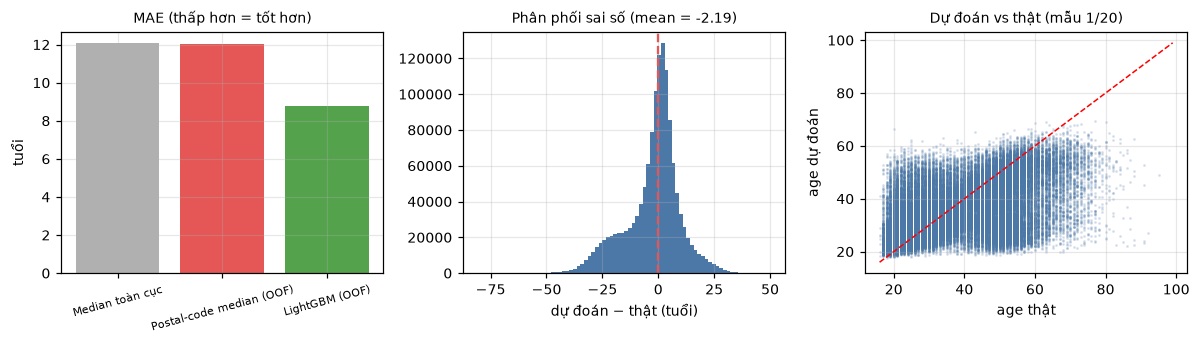

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

names_cmp = cmp["phương pháp"].to_list()
axes[0].bar(names_cmp, cmp["MAE"].to_numpy(), color=["#B0B0B0", "#E45756", "#54A24B"])
axes[0].set_title("MAE (thấp hơn = tốt hơn)", fontsize=9)
axes[0].set_ylabel("tuổi")
axes[0].tick_params(axis="x", labelrotation=15, labelsize=7)

residual = oof[labeled] - y[labeled]
axes[1].hist(residual, bins=80, color="#4C78A8")
axes[1].axvline(0, color="#E45756", ls="--")
axes[1].set_title(f"Phân phối sai số (mean = {residual.mean():+.2f})", fontsize=9)
axes[1].set_xlabel("dự đoán − thật (tuổi)")

axes[2].scatter(y[labeled][::20], oof[labeled][::20], s=1, alpha=0.15, color="#4C78A8")
axes[2].plot([16, 99], [16, 99], "r--", lw=1)
axes[2].set_title("Dự đoán vs thật (mẫu 1/20)", fontsize=9)
axes[2].set_xlabel("age thật")
axes[2].set_ylabel("age dự đoán")
plt.tight_layout()
plt.show()

**Đọc kết quả:**

- MAE giảm ~27% so với median; R² ≈ 0,26 → hành vi mua giải thích được ~1/4 phương sai tuổi.
- Sai số có **trung bình ≈ 0** nhưng độ phân tán lớn: dự đoán bị **co về giữa phân phối**
  (nhìn biểu đồ scatter: các điểm nằm trong dải ~20–60 dù tuổi thật 16–99).
  Đây là hành vi tối ưu cho MAE — đã thử hiệu chỉnh isotonic và MAE **tăng** lên 9,35.
- R² dương nhưng khiêm tốn là **bản chất dữ liệu**, không phải lỗi mô hình.

## Sai số theo nhóm tuổi: mô hình thiên lệch ở đâu?

Bias = trung bình (dự đoán − thật). Bias âm ở nhóm cao tuổi nghĩa là mô hình **dự đoán thấp hơn**
thực tế cho người lớn tuổi.

In [9]:
groups = age_bucket(y[labeled])
rows = []
for gi, label in enumerate(C.AGE_BIN_LABELS):
    sel = groups == gi
    if not sel.any():
        continue
    yt, yp = y[labeled][sel], np.clip(oof[labeled][sel], C.AGE_MIN, C.AGE_MAX)
    rows.append(
        {
            "nhóm tuổi": label,
            "số khách": int(sel.sum()),
            "tỷ lệ (%)": round(float(sel.mean()) * 100, 1),
            "MAE": round(float(np.abs(yt - yp).mean()), 2),
            "bias": round(float((yp - yt).mean()), 2),
        }
    )
pl.DataFrame(rows)

nhóm tuổi,số khách,tỷ lệ (%),MAE,bias
str,i64,f64,f64,f64
"""16-19""",71583,5.3,7.79,7.78
"""20-29""",528358,39.0,5.77,4.92
"""30-39""",234068,17.3,5.79,0.7
"""40-49""",204118,15.1,9.18,-6.56
"""50-59""",226242,16.7,14.22,-13.57
"""60-69""",72623,5.4,18.73,-18.68
"""70+""",19127,1.4,27.31,-27.31


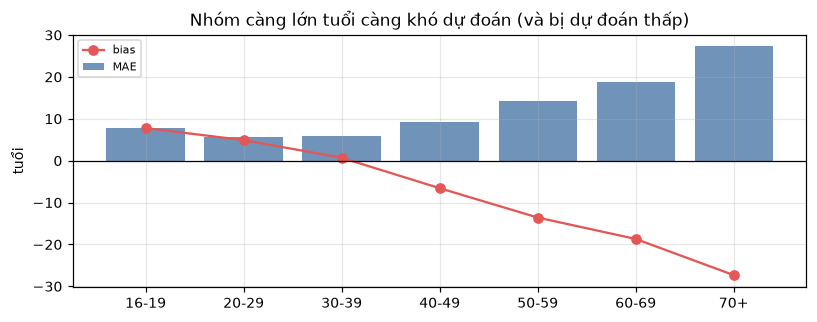

In [10]:
tab = pl.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.5, 3))
xs = np.arange(tab.height)
ax.bar(xs, tab["MAE"].to_numpy(), color="#4C78A8", alpha=0.8, label="MAE")
ax.plot(xs, tab["bias"].to_numpy(), "o-", color="#E45756", label="bias")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xs)
ax.set_xticklabels(tab["nhóm tuổi"].to_list())
ax.set_ylabel("tuổi")
ax.set_title("Nhóm càng lớn tuổi càng khó dự đoán (và bị dự đoán thấp)")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## Feature importance

Đọc gain của LightGBM để biết mô hình dựa vào đâu — đây cũng là kiểm chứng chéo cho các kết luận EDA.

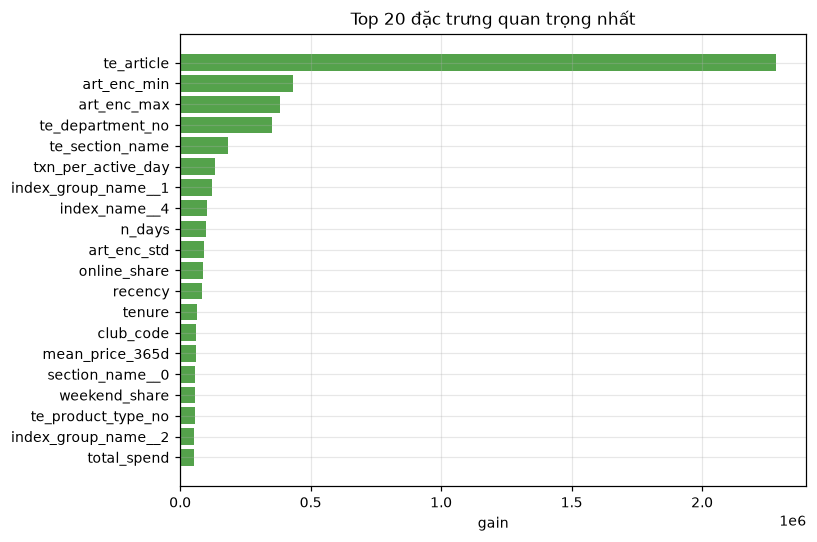

 1. te_article                   2,284,962
 2. art_enc_min                  432,648
 3. art_enc_max                  381,841
 4. te_department_no             351,576
 5. te_section_name              183,372
 6. txn_per_active_day           131,911
 7. index_group_name__1          122,358
 8. index_name__4                102,328
 9. n_days                       97,312
10. art_enc_std                  92,993


In [11]:
booster = lgb.Booster(model_file=str(C.ARTIFACTS / "lgbm_age.txt"))
imp = sorted(zip(names, booster.feature_importance("gain")), key=lambda t: -t[1])[:20]

fig, ax = plt.subplots(figsize=(7.5, 5))
labels_imp = [f for f, _ in imp][::-1]
vals_imp = [g for _, g in imp][::-1]
ax.barh(labels_imp, vals_imp, color="#54A24B")
ax.set_xlabel("gain")
ax.set_title("Top 20 đặc trưng quan trọng nhất")
plt.tight_layout()
plt.show()

for i, (f, g) in enumerate(imp[:10], 1):
    print(f"{i:>2}. {f:<28} {g:,.0f}")

**Đọc kết quả:** 6/10 feature mạnh nhất là **target encoding** (article, department, section,
product type). Điều này khớp hoàn toàn với EDA: tín hiệu ở *sản phẩm*, không phải *tần suất*.

## ⚠️ Sai số thực tế trên nhóm cần điền

MAE 8,80 đo trên nhóm **có nhãn**. Nhưng nhóm **thiếu** age ít hoạt động hơn (EDA mục 6) → sai số
kỳ vọng cao hơn. Ta ước lượng bằng cách trộn MAE theo cơ cấu hoạt động của chính nhóm thiếu.

In [12]:
n_txn = (
    pl.read_parquet(C.ARTIFACTS / "customer_base_features.parquet", columns=["cust_int", "n_txn"])
    .sort("cust_int")
    .get_column("n_txn")
    .to_numpy()
)

miss = np.isnan(y)
edges = np.concatenate([[-1], np.percentile(n_txn[~miss], [20, 40, 60, 80, 95]), [np.inf]])
bin_all = np.digitize(n_txn, edges[1:-1])

err = np.abs(np.clip(oof, C.AGE_MIN, C.AGE_MAX) - y)
per_bin = np.array([err[(bin_all == b) & ~miss].mean() for b in range(6)])
share_missing = np.array([(bin_all[miss] == b).mean() for b in range(6)])
expected = float((per_bin * share_missing).sum())

print("MAE theo nhóm hoạt động:", np.round(per_bin, 2))
print("Cơ cấu nhóm thiếu      :", np.round(share_missing * 100, 1), "%")
print(f"\nMAE OOF trên nhóm có nhãn      : {cv['mae']:.3f} tuổi")
print(f"MAE kỳ vọng trên nhóm thiếu age: {expected:.3f} tuổi  ← con số nên báo cáo")

MAE theo nhóm hoạt động:

 [11.16  9.84  8.79  7.79  6.91  5.98]
Cơ cấu nhóm thiếu      : [36.1 25.  21.5 12.3  4.5  0.5] %

MAE OOF trên nhóm có nhãn      : 8.800 tuổi
MAE kỳ vọng trên nhóm thiếu age: 9.685 tuổi  ← con số nên báo cáo


## Tóm tắt

| Chỉ số | Giá trị |
|---|---|
| MAE (OOF, nhóm có nhãn) | **≈ 8,80 tuổi** |
| MAE kỳ vọng (nhóm thiếu age) | **≈ 9,7 tuổi** |
| RMSE / R² | ≈ 12,3 / ≈ 0,26 |
| Đúng nhóm tuổi 7 mức | ≈ 43,6% |
| Sai ≤ 5 tuổi / ≤ 10 tuổi | ≈ 46% / ≈ 68% |
| Giảm MAE so với median | ≈ 27% |

➡️ Tiếp theo: **05_imputation_report.ipynb** — dùng model đã train để điền tuổi và xuất kết quả.